In [1]:
import tensorflow as tf

from tensorflow.keras import datasets, layers, models
import matplotlib.pyplot as plt

In [2]:
(train_images, train_labels), (test_images, test_labels) = datasets.cifar10.load_data()

# Normalize pixel values to be between 0 and 1
train_images, test_images = train_images / 255.0, test_images / 255.0

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 27s 0us/step


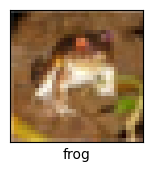

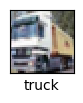

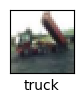

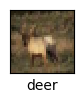

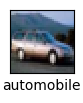

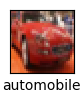

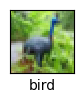

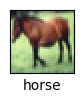

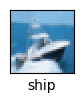

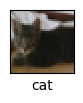

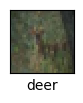

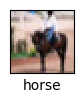

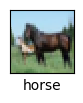

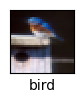

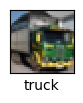

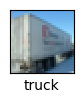

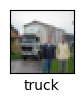

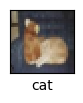

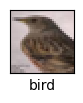

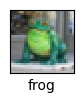

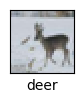

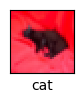

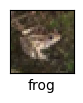

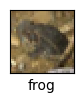

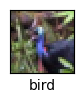

In [3]:
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer','dog', 'frog', 'horse', 'ship', 'truck']

plt.figure(figsize=(10,10))
for i in range(25):
    plt.subplot(5,5,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(train_images[i])
    # The CIFAR labels happen to be arrays,
    # which is why you need the extra index
    plt.xlabel(class_names[train_labels[i][0]])
    plt.show()

In [4]:
from tensorflow.keras import layers, models

model = models.Sequential([
    # Data Augmentation langsung di dalam model (aktif hanya saat training)
    layers.RandomFlip("horizontal", input_shape=(32, 32, 3)),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),

    # Blok Konvolusi 1 (32 filter)
    layers.Conv2D(32, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.Conv2D(32, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.2),

    # Blok Konvolusi 2 (64 filter)
    layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.3),

    # Blok Konvolusi 3 (128 filter)
    layers.Conv2D(128, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.Conv2D(128, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.4),

    # Klasifikasi (Fully Connected)
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.5),
    layers.Dense(10)
])

model.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 32, 32, 3)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 552,874 (2.11 MB)

 Trainable params: 551,722 (2.10 MB)

 Non-trainable params: 1,152 (4.50 KB)

In [5]:
lr_scheduler = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=3,
    verbose=1
)

history = model.fit(
    train_images, train_labels,
    epochs=30,
    batch_size=64,
    validation_data=(test_images, test_labels),
    callbacks=[lr_scheduler]
)

Epoch 1/30
782/782 ━━━━━━━━━━━━━━━━━━━━ 28s 22ms/step - accuracy: 0.3856 - loss: 1.7926 - val_accuracy: 0.4982 - val_loss: 1.4287 - learning_rate: 0.0010
Epoch 2/30
782/782 ━━━━━━━━━━━━━━━━━━━━ 34s 21ms/step - accuracy: 0.5271 - loss: 1.3183 - val_accuracy: 0.5739 - val_loss: 1.2370 - learning_rate: 0.0010
Epoch 3/30
782/782 ━━━━━━━━━━━━━━━━━━━━ 20s 20ms/step - accuracy: 0.5828 - loss: 1.1710 - val_accuracy: 0.6153 - val_loss: 1.1050 - learning_rate: 0.0010
Epoch 4/30
782/782 ━━━━━━━━━━━━━━━━━━━━ 16s 20ms/step - accuracy: 0.6239 - loss: 1.0720 - val_accuracy: 0.6604 - val_loss: 0.9978 - learning_rate: 0.0010
Epoch 5/30
782/782 ━━━━━━━━━━━━━━━━━━━━ 16s 21ms/step - accuracy: 0.6511 - loss: 0.9996 - val_accuracy: 0.6594 - val_loss: 0.9718 - learning_rate: 0.0010
Epoch 6/30
782/782 ━━━━━━━━━━━━━━━━━━━━ 16s 20ms/step - accuracy: 0.6727 - loss: 0.9452 - val_accuracy: 0.6768 - val_loss: 0.9613 - learning_rate: 0.0010
Epoch 7/30
782/782 ━━━━━━━━━━━━━━━━━━━━ 16s 20ms/step - accuracy: 0.6886 - l

313/313 - 2s - 7ms/step - accuracy: 0.8323 - loss: 0.5025


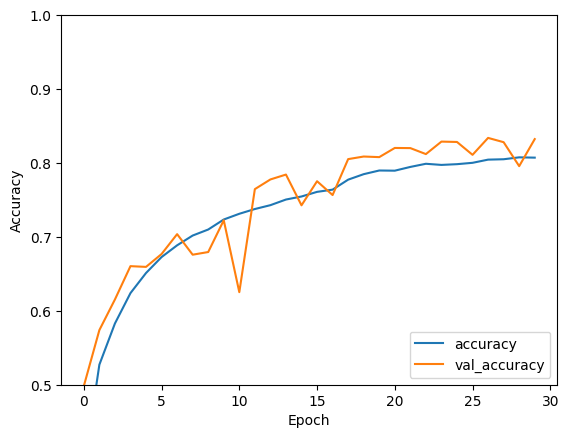

In [6]:
plt.plot(history.history['accuracy'], label='accuracy')
plt.plot(history.history['val_accuracy'], label = 'val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0.5, 1])
plt.legend(loc='lower right')

test_loss, test_acc = model.evaluate(test_images, test_labels, verbose=2)

### Analisis Fase Pembelajaran pada Grafik

#### Fase 1: Eksplorasi dan Fluktuasi Awal (Epoch 1–16)

- Kurva biru (`accuracy`) mengalami peningkatan secara bertahap dari **38,56%** menjadi **76,09%**.
- Kurva oranye (`val_accuracy`) juga menunjukkan tren peningkatan, tetapi mengalami beberapa fluktuasi. Sebagai contoh, nilainya sempat turun menjadi **62,52%** pada Epoch 11 sebelum kembali meningkat menjadi **76,46%** pada Epoch 12.
- Fluktuasi tersebut masih dapat terjadi selama proses pelatihan, terutama ketika model menggunakan `learning_rate = 0.001`, `BatchNormalization`, dan *Data Augmentation*.

#### Fase 2: Titik Balik `ReduceLROnPlateau` (Epoch 17–18)

- `val_loss` sempat mengalami stagnasi pada kisaran **0,62–0,71** selama beberapa epoch. Kondisi ini memicu callback `ReduceLROnPlateau` untuk menurunkan *learning rate* menjadi setengah dari nilai sebelumnya, yaitu dari `0.001` menjadi `0.0005` setelah Epoch 17.
- Dampak penurunan *learning rate* mulai terlihat pada Epoch 18. `val_accuracy` meningkat dari **75,66%** menjadi **80,52%**, sementara `val_loss` mengalami penurunan dari **0,7111** menjadi **0,5878**.

#### Fase 3: Konvergensi dan Stabilitas (Epoch 18–30)

- Setelah Epoch 18, kurva oranye (`val_accuracy`) cenderung stabil pada kisaran **80%–83%**.
- Performa terbaik dicapai pada **Epoch 27**, dengan `val_accuracy` sebesar **83,39%** dan `val_loss` sebesar **0,4973**.
- Pada akhir pelatihan, yaitu Epoch 30, model memperoleh `val_accuracy` sebesar **83,23%**.
- Meskipun terjadi penurunan sementara pada Epoch 29 menjadi **79,57%**, performa kembali meningkat pada Epoch 30 menjadi **83,23%**.

## Analisis Akhir dan Perbandingan dengan Praktikum 2

Seluruh angka pada bagian ini diambil dari output aktual notebook.

### Ringkasan Hasil

| Item | Nilai |
|---|---|
| Akurasi training akhir (Epoch 30) | 0.8070 |
| Akurasi validasi terbaik (Epoch 27) | 0.8339 |
| Akurasi data uji akhir | **0.8323** |
| Test loss akhir | 0.5025 |
| Total parameter | 552.874 |
| Target tugas | di atas 80% |

### Perbandingan dengan Praktikum 2

| Model | Akurasi Uji | Test Loss | Epoch |
|---|---:|---:|---:|
| Praktikum 2 (CNN sederhana) | 0.7168 | 0.8555 | 10 |
| Tugas 1 (CNN + augmentasi + BatchNorm) | **0.8323** | **0.5025** | 30 |

1. **Target 80% tercapai.** Akurasi data uji **83.23%**, yaitu **3.23 poin** di atas target dan **11.55 poin** di atas Praktikum 2.
2. **Penurunan error cukup besar.** Error turun dari **28.32%** menjadi **16.77%**, sehingga sekitar **40.78%** kesalahan sebelumnya berhasil diperbaiki.
3. **Test loss turun.** Loss turun dari **0.8555** menjadi **0.5025**, sekitar **41.26%** lebih rendah.

### Faktor Penyebab Peningkatan

1. **Arsitektur lebih dalam.** Tiga blok konvolusi (32, 64, 128 filter) dengan dua lapis konvolusi per blok menangkap pola citra secara bertingkat, dibandingkan Praktikum 2 yang memakai tiga lapis konvolusi tanpa BatchNormalization dan tanpa augmentasi.
2. **Batch Normalization** menstabilkan distribusi aktivasi sehingga training lebih stabil dan learning rate 0.001 dapat dipakai.
3. **Data augmentation** (`RandomFlip`, `RandomRotation`, `RandomZoom`) memperluas variasi data latih dan menekan overfitting.
4. **Dropout berjenjang** (0.2, 0.3, 0.4, 0.5) mengurangi ketergantungan pada neuron tertentu.
5. **ReduceLROnPlateau** menurunkan learning rate dari 0.001 ke 0.0005 pada Epoch 17 ketika `val_loss` stagnan. Setelah itu akurasi validasi melonjak dari **75.66%** menjadi **80.52%** pada Epoch 18.
6. **Durasi training lebih panjang.** Model dilatih 30 epoch, bukan 10 epoch, sehingga sempat mencapai akurasi validasi terbaik **83.39%** pada Epoch 27.

### Catatan Penting

1. **Akurasi validasi lebih tinggi daripada akurasi training.** Pada Epoch 30, akurasi training **0.8070** sedangkan akurasi validasi **0.8323**. Hal ini wajar karena saat training data augmentation dan dropout aktif, sedangkan saat validasi keduanya nonaktif.
2. **Belum ada overfitting yang berarti.** Selisih training dan validasi justru negatif, sehingga model masih dapat ditingkatkan dengan training lebih lama.
3. **Data uji dipakai sebagai `validation_data`.** `ReduceLROnPlateau` memantau `val_loss` yang berasal dari data uji, sehingga jadwal learning rate ikut dipengaruhi data uji. Akurasi akhir tetap diukur pada data uji yang sama, tetapi hasil ini sedikit optimistis karena pemilihan epoch dan penurunan learning rate tidak sepenuhnya buta terhadap data uji. Untuk evaluasi yang lebih ketat, data uji seharusnya dipisahkan dari validation set.
4. **Akurasi terbaik ada di Epoch 27 (83.39%), bukan Epoch 30.** Selisihnya hanya **0.16 poin**, sehingga pemilihan model akhir tidak banyak berubah.